__Retail Sales Data Analysis and Visualization__ 

Loading data and Importing modules 

In [5]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

df=pd.read_csv('sales_data.csv')

df.head()

,date,product,category,region,units_sold,unit_price,discount_pct,sales_channel
0,2025-01-05,Laptop,Electronics,South,3,52000,5,Online
1,2025-01-12,Headphones,Electronics,North,18,1800,10,Store
2,2025-01-19,Office Chair,Furniture,West,7,6500,0,Online
3,2025-02-03,Notebook,Stationery,East,60,80,0,Store
4,2025-02-11,Desk,Furniture,South,4,12000,8,Online


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   date           36 non-null     str  
 1   product        36 non-null     str  
 2   category       36 non-null     str  
 3   region         36 non-null     str  
 4   units_sold     36 non-null     int64
 5   unit_price     36 non-null     int64
 6   discount_pct   36 non-null     int64
 7   sales_channel  36 non-null     str  
dtypes: int64(3), str(5)
memory usage: 2.4 KB


Calculate the revenue for each sales record using the quantity sold, unit price, and discount percentage.

In [7]:
df["revenue"] = df['units_sold'] * (df['unit_price'] *(100- df['discount_pct']) / 100 ).round(2)

In [8]:
df.head()

,date,product,category,region,units_sold,unit_price,discount_pct,sales_channel,revenue
0,2025-01-05,Laptop,Electronics,South,3,52000,5,Online,148200.0
1,2025-01-12,Headphones,Electronics,North,18,1800,10,Store,29160.0
2,2025-01-19,Office Chair,Furniture,West,7,6500,0,Online,45500.0
3,2025-02-03,Notebook,Stationery,East,60,80,0,Store,4800.0
4,2025-02-11,Desk,Furniture,South,4,12000,8,Online,44160.0


**Let Create Some Viualization using Matplotlib , seaborn**

1 . Line chart showing monthly revenue trends.

In [9]:

df['date']=pd.to_datetime(df['date'])
df['month']=df['date'].dt.month # int 
# df['month']=df['date].dt.month_name() -> str 

monthly=df.groupby('month',as_index=False)["revenue"].sum()

monthly



,month,revenue
0,1,222860.0
1,2,131610.0
2,3,144420.0
3,4,73248.0
4,5,175115.0
5,6,281060.0
6,7,159425.0
7,8,229470.0
8,9,93730.0
9,10,201015.0


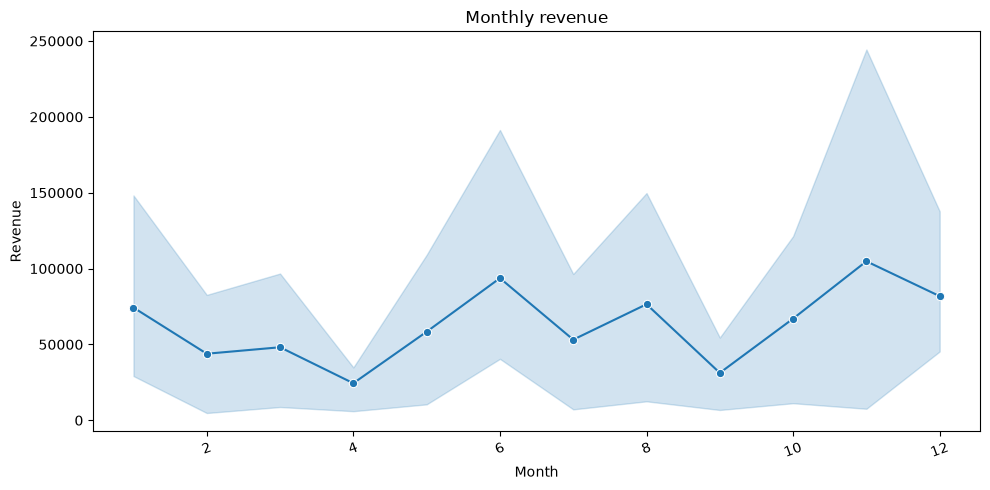

In [15]:
fig,ax=plt.subplots(figsize=(10,5))

sns.lineplot(x=df['month'],y=df['revenue'],marker='o',ax=ax)
ax.set(title="Monthly revenue",xlabel="Month",ylabel="Revenue")
ax.tick_params(axis="x",rotation=20) # the axis to which parametrs are appplied (def : both)
plt.tight_layout()


2.Bar chart comparing revenue across product categories.

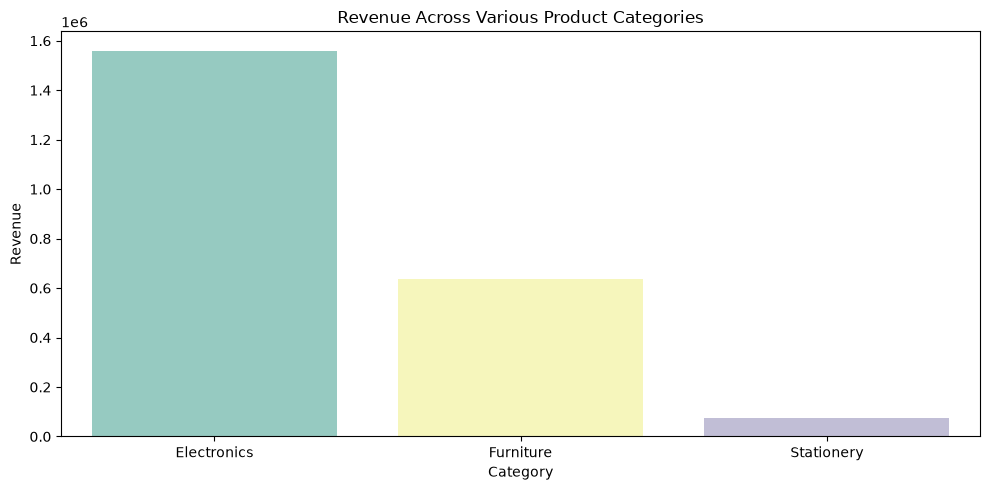

In [20]:
fig,ax=plt.subplots(figsize=(10,5))
cat=df.groupby('category',as_index=False)['revenue'].sum().sort_values("revenue",ascending=False)

sns.barplot(data=cat,x="category",y="revenue",palette='Set3',ax=ax,hue='category',legend=False)

ax.set(title="Revenue Across Various Product Categories",xlabel="Category",ylabel="Revenue")
plt.tight_layout()
# Starting in Seaborn 0.13.0, passing a palette requires an explicit hue mapping
#  so that color assignment is tied directly to a data variable rather than implicitly tied to the positional axis.

3.Heatmap comparing revenue across regions and product categories.

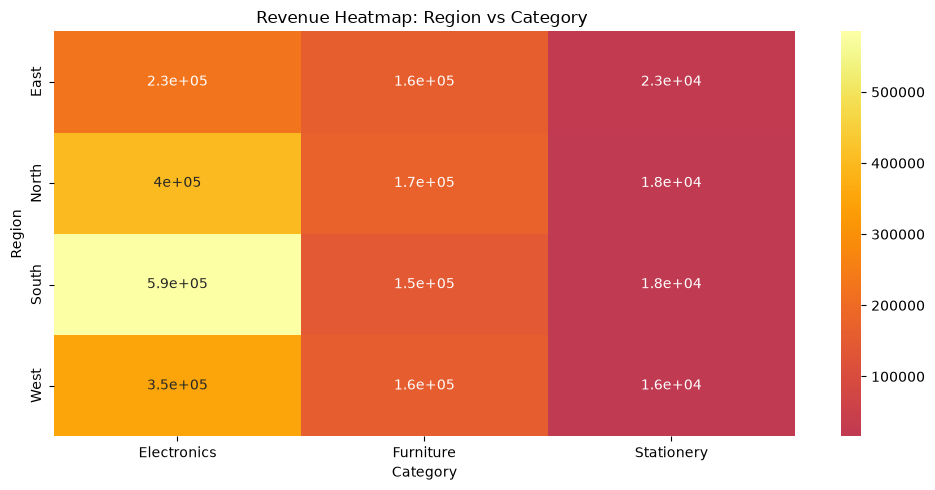

In [26]:
# Heatmap - rep values using colors , It is often used to visualize correlation Matrix 

fig,ax=plt.subplots(figsize=(10,5))
heat_df=df[['category','region','revenue']]

corr = heat_df.pivot_table(
    index='region',
    columns='category',
    values='revenue',
    aggfunc='sum'
).fillna(0)

sns.heatmap(corr,annot=True,cmap='inferno',center=0,ax=ax)

ax.set(title="Revenue Heatmap: Region vs Category ", xlabel="Category", ylabel="Region")
ax.tick_params()
plt.tight_layout()


4.Scatter plot showing the relationship between units sold and revenue.

[Text(0.5, 1.0, 'Scatter plot : Units sold vs revenue'),
 Text(0.5, 0, 'Units Sold'),
 Text(0, 0.5, 'Revenue')]

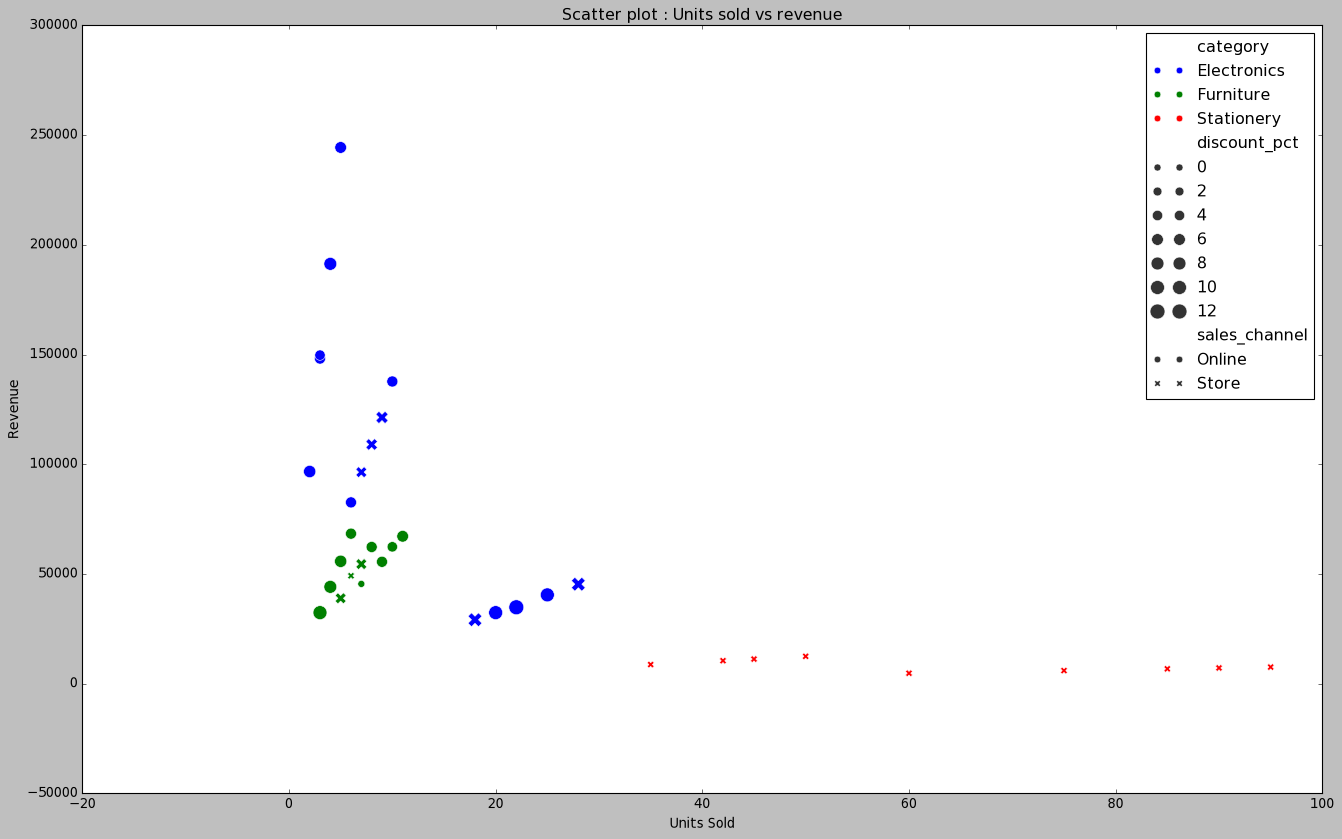

In [38]:
fig,ax=plt.subplots(figsize=(20,12))
plt.style.use('classic')
sns.scatterplot(x=df['units_sold'],y=df['revenue'], hue=df['category'],
                    style=df["sales_channel"], size=df["discount_pct"], sizes=(40, 180),ax=ax)
ax.set(title="Scatter plot : Units sold vs revenue",xlabel="Units Sold",ylabel="Revenue")


5.Histogram showing the distribution of revenue per sales record.

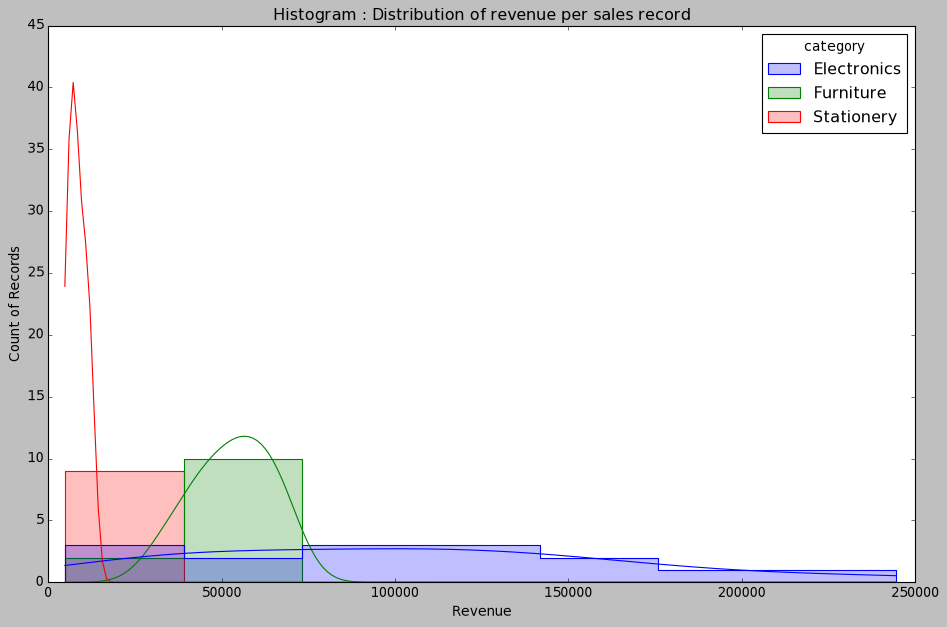

In [49]:
fig,ax=plt.subplots(figsize=(12,8))
df.head()
sns.histplot(data=df,x="revenue",kde=True, element="step",ax=ax,hue='category') # kde=True overlays a smoothed density curve.

ax.set(title="Histogram : Distribution of revenue per sales record",xlabel="Revenue",ylabel="Count of Records")
fig.tight_layout()

6.Bar chart comparing revenue from online and in-store sales.

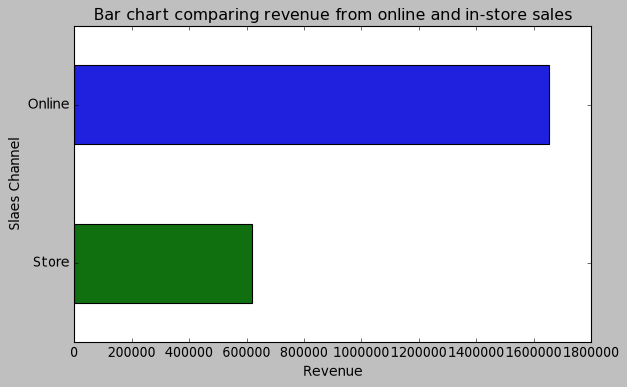

In [63]:
channel = df.groupby("sales_channel", as_index=False)["revenue"].sum() # as_index=False means that the column you are grouping by will remain a regular column in the output DataFrame rather than becoming the row index.
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=channel,x='revenue',y='sales_channel',hue='sales_channel',legend=False,ax=ax,width=0.5)

ax.set(title="Bar chart comparing revenue from online and in-store sales",xlabel="Revenue",ylabel="Slaes Channel")

plt.tight_layout()



7.Calculate and display total revenue, total units sold, average revenue per record, and the top-performing product, category, and region.

In [69]:
total_revenue=df['revenue'].sum()
total_units_sold=df['units_sold'].sum()
avg_revenue_per_record=df['revenue'].mean()
top_category=df.groupby('category')['revenue'].sum().idxmax()
top_product=df.groupby('product')['revenue'].sum().idxmax()
top_region=df.groupby('revenue')['region'].sum().sort_values(ascending=False).values[0]

print(f"""
      Total revenue : {total_revenue} 
      Total units Sold : {total_units_sold}
      Average Revenue per Record : {avg_revenue_per_record}
      Top Category : {top_category}
      Top Product : {top_product}
      Top Region : {top_region} """
      )

# \n escape sequence adds a newline to the output, but it does not allow you to press Enter inside a normal quoted string.
# print(
#     f"Total revenue : {total_revenue}\n"
#     f"Total units Sold : {total_units_sold}\n"
#     f"Average Revenue per Record : {avg_revenue_per_record}\n"
#     f"Top Category : {top_category}\n"
#     f"Top Product : {top_product}\n"
#     f"Top Region : {top_region}"
# )



      Total revenue : 2271783.0 
      Total units Sold : 828
      Average Revenue per Record : 63105.083333333336
      Top Category : Electronics
      Top Product : Laptop
      Top Region : West 


**All Plots Together as One**

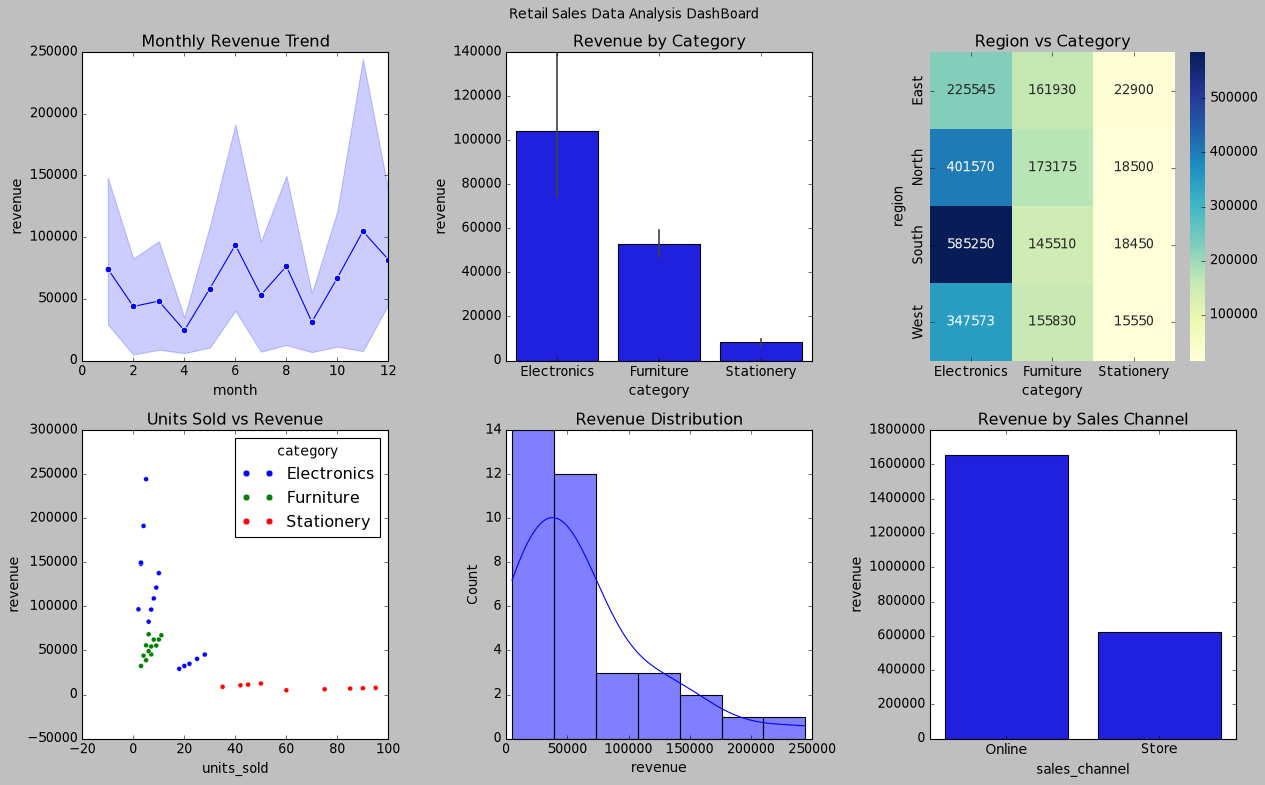

In [78]:
fig, ax = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle("Retail Sales Data Analysis DashBoard")
# Line plot
sns.lineplot(
    data=df, x="month", y="revenue",
    marker="o", ax=ax[0, 0]
)
ax[0, 0].set_title("Monthly Revenue Trend")

#Bar plot
sns.barplot(
    data=df, x="category", y="revenue",
    ax=ax[0, 1]
)
ax[0, 1].set_title("Revenue by Category")

# Heatmap
sns.heatmap(
    corr, annot=True, fmt=".0f",
    cmap="YlGnBu", ax=ax[0,2]
)
ax[0, 2].set_title("Region vs Category")

# Scatter plot
sns.scatterplot(
    data=df, x="units_sold", y="revenue",
    hue="category", ax=ax[1, 0]
)
ax[1, 0].set_title("Units Sold vs Revenue")

#  Histogram
sns.histplot(
    data=df, x="revenue", kde=True,
    ax=ax[1, 1]
)
ax[1, 1].set_title("Revenue Distribution")

#Sales channel bar plot
sns.barplot(
    data=channel, x="sales_channel", y="revenue",ax=ax[1, 2]
)
ax[1, 2].set_title("Revenue by Sales Channel")

plt.tight_layout()
plt.show()
fig.savefig("SalesAnlysisDashBoard.png",dpi=150,bbox_inches="tight")

**End of Project**